# How to use autoMCCD-lite: one record in, one certificate out

This notebook walks you through a single run of the pipeline from the outside, the way a registry
system would use it. You send one clinical record to the running api, and you get back a WHO
Medical Certificate of Cause of Death (MCCD) coded in ICD-11, with a route that says whether a
human needs to look at it, and the reasons why.

Inside the api the record goes through three steps:

1. **Draft**: a language model writes a draft certificate from the record.
2. **Check**: the code checks the draft against ten rules and codes it with the WHO's own tools,
   giving the model one chance to fix what failed.
3. **Decide**: every problem the checks found becomes a reason code; no reasons means `auto`,
   any reason means `review`.

You will see four pictures of the same result, each answering one question:

1. **The certificate as the WHO form**: what would be printed.
2. **The record with the evidence highlighted**: where every certified line came from.
3. **The flow diagram**: what each step did to this record, with the live numbers.
4. **The charts over an evaluation run**: how the pipeline does over the 17 provided cases.

Everything here runs live against your api, so the outputs you see are yours. Start it in a
terminal with `uv run automccd-lite serve` (it starts the WHO ICD-API container first, which takes
about a minute to load its release the first time) and wait for `/readyz` to say ready.


In [1]:
import json, time
import httpx
from _helpers import *  # display helpers; the pipeline itself lives in automccd_lite
from automccd_lite.config import ROOT, settings

cfg = settings()
API = f"http://localhost:{cfg.env.api_port}"
ready = httpx.get(f"{API}/readyz", timeout=30).json()
print(json.dumps(ready, indent=2))
assert ready["ready"], "start the api with `uv run automccd-lite serve` and wait for its startup line"

{
  "ready": true,
  "components": {
    "icd_api": true,
    "store": true,
    "model_configured": true
  }
}


## 1. The input: a death record

A record is a small JSON document: who died (`record_id`, `sex`, `age` with its `age_unit`) and one
or more free-text `notes`, each with a `name`. The names matter later: when the model cites
evidence, it names the note it quoted from, and the rule check compares the quote with that note.

S01 is the first of the teaching scenarios the client gave us. Read the narrative once before you
run anything, and decide for yourself what the chain of causes was. You will compare your answer
with the model's in a moment.


In [2]:
record = load_record("S01")
show_json(record)

{
  "record_id": "S01",
  "sex": "male",
  "age": 49.0,
  "age_unit": "years",
  "registry_info": null,
  "notes": [
    {
      "name": "case_narrative",
      "text": "A male aged 49 years was admitted to hospital with a history of fever, disorientation and drow…
    }
  ]
}


## 2. Send it to the api

`POST /certify` takes the record and runs all three steps before it answers, which is why a call
takes a few seconds. Most of that time is the language model writing the draft; the WHO coding
calls take milliseconds. You get one JSON body back.


In [3]:
t0 = time.perf_counter()
r = httpx.post(f"{API}/certify", json=record.model_dump(mode="json"), timeout=300)
r.raise_for_status()
resp = r.json()
print(f"HTTP {r.status_code} in {time.perf_counter() - t0:.1f} s")
print("route  :", resp["route"])
print("reasons:", resp["reasons"])

HTTP 200 in 8.7 s
route  : review
reasons: ['fix:rules', 'model:low_confidence', 'quality:BER-CE-1']


## 3. Read the response

The body has eight parts. Read them in this order:

- `route` and `reasons`: the decision from Step 3. `auto` means nothing stopped the certificate
  from being accepted as written; `review` means a human should look, and `reasons` lists every
  reason code that applies. Each code reads `source:what`: a reviewer who sees
  `model:low_confidence` and `quality:FER-CE-931` knows exactly what to check.
- `certificate`: the MCCD the model wrote in Step 1, in the strict JSON shape the prompt's schema
  defines.
- `coding`: what the WHO tools said in Step 2: the ICD-11 code of each line, how well each term
  matched (`match_scores`), and the underlying cause of death (UCOD) that the WHO cause selector
  (DORIS) chose, `underlying_cause`.
- `versions`: the prompt hash, the model and the ICD release that produced this. Two certificates
  with the same versions are comparable; two with different ones are not.
- `usage` and `timings_ms`: what it cost, per step.

The rule check details and the raw WHO replies are not in the body. They are saved with the
certificate, and you will read them in section 6.


In [4]:
show_json(resp, keys=["record_id", "route", "reasons", "coding", "versions", "usage", "timings_ms"])

{
  "record_id": "S01",
  "route": "review",
  "reasons": [
    "fix:rules",
    "model:low_confidence",
    "quality:BER-CE-1"
  ],
  "coding": {
    "underlying_cause": "1G41",
    "underlying_cause_full": "1G41",
    "codes": {
      "part1": [
        "1G41"
      ],
      "part2": [
        "1B54",
        "5A11",
        "NE84"
      ]
    },
    "match_scores": [
      1.0
    ],
    "quality_issues": [
      "BER-CE-1"
    ],
    "cause_warning": "The following conditions - NE84 - were reported without an external cause, a default ex…
  },
  "versions": {
    "prompt_version": "4.7",
    "prompt_sha1": "d051044cd4a12f9a46085b23869a4ed70623719e",
    "schema_version": "v1.1",
    "model": "gpt-5-nano-2025-08-07",
    "icd_release": "2026-01",
    "package_version": "0.1.0"
  },
  "usage": {
    "prompt_tokens": 11160,
    "completion_tokens": 849,
    "reasoning_tokens": 0,
    "calls": 2
  },
  "timings_ms": {
    "draft": 3449,
    "check": 2872,
    "decide": 0
  }
}


## 4. The certificate as the WHO form

Part I is read from the bottom up: the condition on the lowest used line started the sequence,
and each line above it is a consequence of the line below. Line 1a is what the person died of
directly. The interval column says how long before death each condition began, so intervals must
not shrink as you go down the chain. Part II holds conditions that contributed but were not part
of that sequence.

The small blue code at the right of each line is the ICD-11 code the WHO term coder (autocode)
gave the term. If a line has no code, the coder could not match the wording, and the reasons say
so with `who:line_uncoded`.


In [5]:
coding = resp.get("coding") or {}
render_mccd(resp["certificate"], coding.get("codes"), title=f"{resp['record_id']}: route {resp['route']}")

## 5. The record with the evidence highlighted

Every line the model certifies must quote the record word for word: the `evidence_span` must
appear, character for character up to layout, in the note the `evidence_field` names. That is rule
V1 (exact quote). The highlighter below uses the same tolerant comparison as V1, so what you see
highlighted is what V1 accepted. A span V1 rejects shows up at the bottom in red: that is an
invented or edited quote, and the pipeline sends such a draft back to the model for one fix before
it goes to a reviewer.

Read the superscript labels: `1a`, `1b` are Part I lines, `II.1` is the first Part II entry.


In [6]:
highlight_spans(record, resp["certificate"])

## 6. What was saved: the row and the file

The api saves every result twice under the `store/` folder. The JSON body you just received is
written to `store/certificates/{date}/{time}Z_{record_id}.json`, and one row goes to the
`certificates` table in `store/certificates.sqlite` with everything the body leaves out: the rule
check (`rule_check`), both fixes, and the raw replies of the WHO tools (`who_replies`). The row is
what a reviewer or an audit reads; the file is what a downstream system picks up.

The file is written first and the row records its path, so a row never points at a missing file.


In [7]:
from automccd_lite.store import db_path, latest_row, stored_file

row = latest_row("S01")
print("database     :", db_path().relative_to(ROOT))
print("row id       :", row.id, "created", row.created_at.isoformat(timespec="seconds"))
print("route/reasons:", row.route, row.reasons)
print("file_path    :", row.file_path, "exists:", stored_file(row.file_path).is_file())
print("file keys    :", sorted(json.loads(stored_file(row.file_path).read_text(encoding="utf-8"))))
print("rule_check   :", {k: row.rule_check[k] for k in ("schema_ok", "rules_passed", "broken_rules", "rules_fixed", "fix_rejected", "terms_fixed", "confidence")})
print("who_replies  :", list((row.who_replies or {}).keys()))

database     : store\certificates.sqlite
row id       : 3 created 2026-11-02T08:50:26
route/reasons: review ['fix:rules', 'model:low_confidence', 'quality:BER-CE-1']
file_path    : certificates/2026-11-02/085026Z_S01.json exists: True
file keys    : ['certificate', 'coding', 'reasons', 'record_id', 'route', 'timings_ms', 'usage', 'versions']
rule_check   : {'schema_ok': True, 'rules_passed': True, 'broken_rules': [], 'rules_fixed': True, 'fix_rejected': None, 'terms_fixed': None, 'confidence': 'moderate'}
who_replies  : ['codes', 'uncoded_part1', 'match_scores', 'autocode', 'doris', 'codedit', 'codedit_cause']


## 7. The flow diagram, with this record's live values

The saved row holds enough to rebuild the whole `Result` object, the provenance included. From it
you can draw what happened in each step: the model status and the time it took; which rules broke,
whether a fix ran and was adopted, the codes and the underlying cause; and the route with its
reasons. Orange boxes are where this record hit a problem; blue and green ones passed.


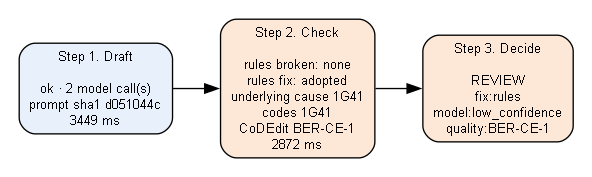

In [8]:
from automccd_lite.models import Coding, CodingSummary, Result, RuleCheck, Usage, Versions

result = Result(
    record_id=row.record_id, route=row.route, reasons=row.reasons, certificate=row.certificate,
    coding=CodingSummary(**row.coding) if row.coding else None, versions=Versions(**row.versions),
    usage=Usage(**row.usage), timings_ms=row.timings_ms, draft_status=row.draft_status,
    rule_check=RuleCheck(**row.rule_check) if row.rule_check else None,
    who_replies=Coding(**row.who_replies) if row.who_replies else None, icd_error=row.icd_error,
)
flow_diagram(result)

## 8. The evaluation: how the pipeline does on the 17 provided cases

One record tells you little. The mini harness runs the pipeline on the 17 provided scenarios (the
client's teaching cases, each with a reference certificate, the "gold" answer), scores each one,
and writes a `runs/provided_<time>Z/` folder with `results.json` and a readable `summary.md`. It
runs in-process (no api, nothing saved to the store), so you can run it from this notebook. It
makes about 24 model calls and takes a minute or two.

The numbers that matter, and you will see each one below:

- **Rules passed, first try**: how often the model's first draft passed all ten rules. This is the
  model's discipline.
- **Rules passed, after the fix**: the same after the one fix the pipeline allows. The gap between
  the two is what the fix buys you.
- **Auto share**: how many certificates needed no human. Expect this to be low; the checks are
  deliberately strict, and `model:low_confidence` alone sends a certificate to review.
- **Underlying cause matches the reference**: whether the WHO cause selector (DORIS) picked the
  same underlying cause (UCOD) from the model's chain as from the reference certificate. Both
  chains are coded through the same tools, so this compares code with code, never word with word.

One warning before you read them: this model does not return the same draft twice, so each number
moves by several points from run to run on 17 cases. Treat one run as a sketch. When you change the
prompt or the model, run the harness a few times and compare the ranges, not two single runs.


In [9]:
from automccd_lite.eval import run

res = run("provided", quiet=True)
s = res["summary"]
print("run folder                 :", res["run_dir"].relative_to(ROOT))
print("rules passed, first try    :", s["rules_passed_first_try"], "%")
print("rules passed, after the fix:", s["rules_passed_after_fix"], "%   (rules fixed:", s["rules_fixed"], ")")
print("auto share                 :", s["auto_share"], "%")
print("cause matches the reference:", s["cause_matches_reference"], "% of", s["causes_compared"])
print("reasons seen               :", s["reasons"])

run folder                 : runs\provided_085029Z
rules passed, first try    : 41.2 %
rules passed, after the fix: 64.7 %   (rules fixed: 10 )
auto share                 : 0.0 %
cause matches the reference: 47.1 % of 17
reasons seen               : {'model:low_confidence': 17, 'quality:BER-CE-1': 2, 'rule:V3': 1, 'fix:rules': 10, 'rule:V1': 3, 'rule:V2': 2, 'quality:BER-CE-10': 2, 'who:low_match': 1, 'quality:BER-CE-22': 2, 'quality:FER-CE-934': 1, 'quality:FER-CE-993': 1, 'rule:V7': 1}


### Reading the charts

Left: the routes. Middle: which rules broke on the first draft (orange) and how many were still
broken after the fix (blue); a rule that drops to zero is one the fix repairs reliably. Right: how
the model's underlying cause compared with the reference's, by DORIS stem code. Same family means
the same code before the dot, such as `BA41.0` and `BA41.Z`.

Below them, the time per case by step. Nearly all of it is Draft, the model call; a long Check
segment means a fix call ran. Then the per-case table, which is the same information the
`summary.md` file carries.


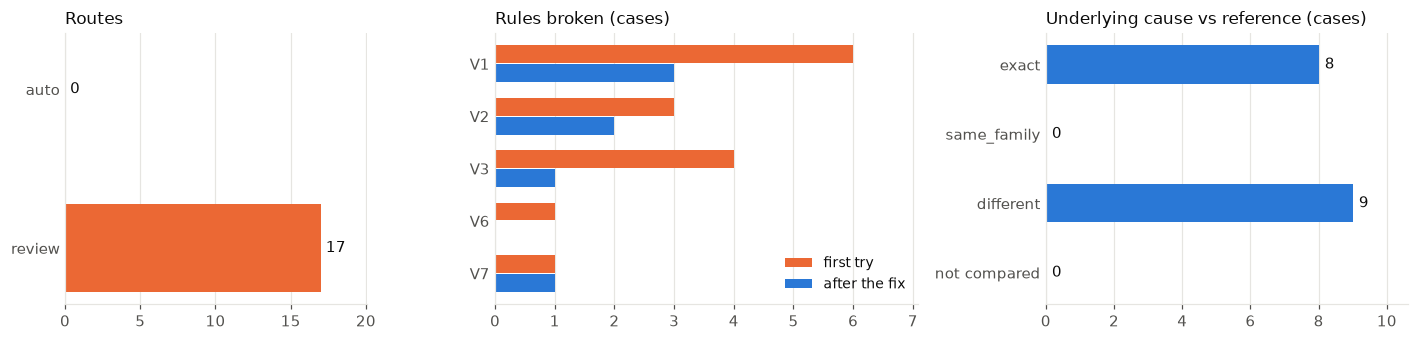

In [10]:
charts(res["rows"]);

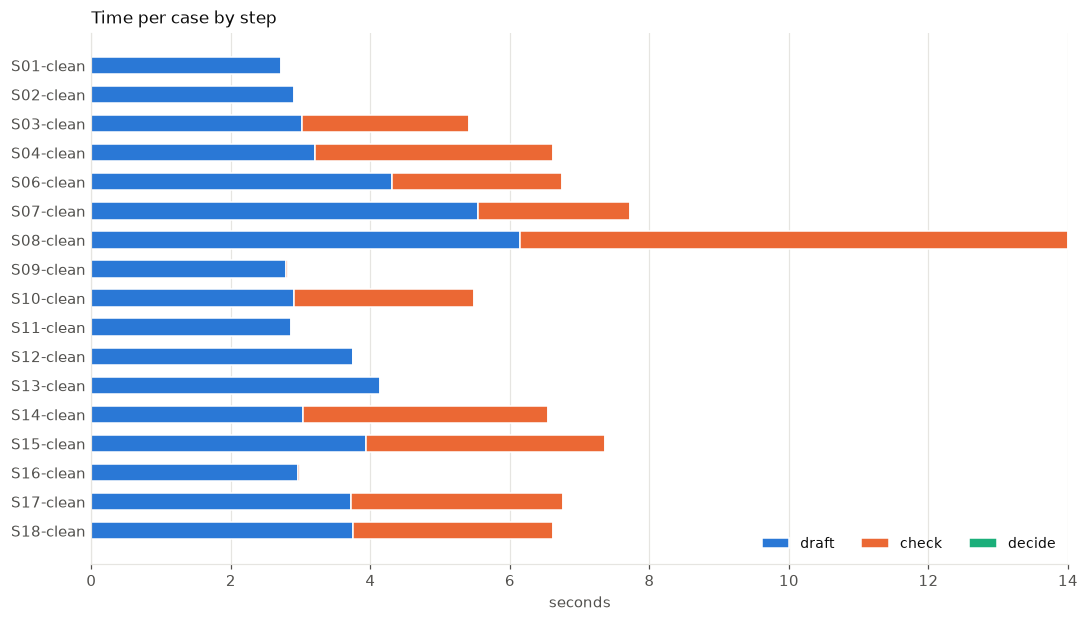

In [11]:
timings_chart(res["rows"]);

In [12]:
reason_table(res["rows"])

case,route,reasons,rules first → final,cause model / reference,match
S01-clean,review,"model:low_confidence, quality:BER-CE-1",– → –,1G41 / 1B54,different
S02-clean,review,model:low_confidence,– → –,8B11.5Z / 8B11.5Z,exact
S03-clean,review,"rule:V3, fix:rules, model:low_confidence","V1,V3 → V3",DC3Y / DC32.3,different
S04-clean,review,"rule:V1, fix:rules, model:low_confidence",V1 → V1,BA41.Z / BA41.Z,exact
S06-clean,review,"rule:V2, fix:rules, model:low_confidence, quality:BER-CE-10",V2 → V2,CA22.Z / CA22.Z,exact
S07-clean,review,"fix:rules, model:low_confidence",V3 → –,5A14 / 5A11,different
S08-clean,review,"rule:V2, fix:rules, model:low_confidence, who:low_match, quality:BER-CE-1","V2,V3 → V2",PB6Z / LA89.Z,different
S09-clean,review,model:low_confidence,– → –,DC50.Z / DA63.Y,different
S10-clean,review,"fix:rules, model:low_confidence","V1,V3 → –",LA88.2Z / LA88.2Z,exact
S11-clean,review,"model:low_confidence, quality:BER-CE-10",– → –,BA6Z / 2B90.3Z,different


## 9. What to try next

- **Change the prompt** in `prompts/mccd/v4.7.md` (copy it to `v4.8.md` and set
  `draft.prompt_version` in `config/default.yaml`). The `prompt_sha1` in every certificate changes
  with it, so runs stay comparable only within a version. Rerun the harness and compare.
- **Change the model** with `LLM_MODEL` in `.env`. A stronger model raises the first-try number
  before anything else.
- **Run the harder set** with `uv run automccd-lite eval --set dlc`: 40 records with OCR noise,
  cut pages, a second patient's page, handwritten notes, and the six coroner cases the pipeline
  must decline. They are scored on behaviour: did the pipeline take the right action, and did it
  avoid what each case forbids?
- **Open `mccd_guide.ipynb`** for the long version: what a death certificate is, how ICD-11 and
  DORIS work, and each of the three steps run on S01 with its options.
